# L1.3 · Turn many transactions into one customer row

**PowerPoint slides** 21  
**Course data** card_transactions.csv.gz and customers_raw.csv

### The problem

A customer can have many card payments. How can we describe their activity in one row?

### What this demo shows

Turn the recorded payments into a count, a total and the date of the most recent payment. Join the results back to customers, including someone with no matching payments.

### Why we’re doing it

Models often need one row per person. A short summary lets another person understand the recorded activity without reading every transaction.

**If this is your first ML activity**, open [00 · Your first ML workflow](00_Start_Here_Your_First_ML_Workflow.ipynb) first. For the simpler examples of model types and repeated checking, see [01 · Regression and classification](01_Regression_and_Classification.ipynb) and [03 · K-fold cross-validation](03_K_Fold_Cross_Validation.ipynb).

Here, read the plain-English explanation before each cell. Run **Setup**, then work down the page with **Shift + Enter**.

## Setup · Load the data

Read four event columns and the first 25,000 transactions. Pick three IDs that repeat so we can trace them through the demonstration. The first few lines locate the course data folder. You can
run the whole cell as written.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

working_folder = Path.cwd()
data_folder = next(
    (folder / 'data' for folder in (working_folder, *working_folder.parents)
     if (folder / 'data' / 'property_valuations.csv').is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError('Open the extracted course folder in Jupyter or VS Code.')

event_columns = ["customer_id", "txn_ts", "amount_aed", "merchant_category"]
events = pd.read_csv(data_folder / "card_transactions.csv.gz", usecols=event_columns,
                     nrows=25_000, parse_dates=["txn_ts"])
cutoff = pd.Timestamp("2025-04-05")
events = events[events["txn_ts"] < cutoff].copy()
customer_columns = ["customer_id", "salary_transfer", "monthly_salary_aed"]
customers = pd.read_csv(data_folder / "customers_raw.csv", usecols=customer_columns)
customers = customers.drop_duplicates("customer_id")
focus_ids = events["customer_id"].value_counts().head(3).index
display(events[events["customer_id"].isin(focus_ids)].head(6))

,txn_ts,customer_id,amount_aed,merchant_category
663,2025-04-01 08:35:49,HGB1142546,274.84,Electronics
4340,2025-04-01 15:56:29,HGB1214528,51.36,Grocery
4390,2025-04-01 16:02:50,HGB1028434,555.05,Travel
4764,2025-04-01 16:45:19,HGB1028434,620.47,Online_Gaming
4813,2025-04-01 16:52:01,HGB1028434,765.48,Online_Gaming
4843,2025-04-01 16:55:12,HGB1028434,748.64,Travel


## 1 · Make repeated categories cheaper to store

**What we’re doing.** Compare the space needed to store merchant categories as text and as reusable categories.

**Why we’re doing it.** Merchant labels repeat thousands of times. Using the same short code for repeated labels can make a large file easier to work with.

**What to look for.** Both columns describe the same category labels. Compare the bytes on this slice.

In [2]:
category = events["merchant_category"]
print(f"Text bytes: {category.memory_usage(index=False, deep=True):,}")
print(f"Category bytes: {category.astype('category').memory_usage(index=False, deep=True):,}")

Text bytes: 447,760
Category bytes: 25,268


## 2 · Count, total, and find the most recent event

**What we’re doing.** For each customer, find their last payment, count their payments and add what they spent.

**Why we’re doing it.** These numbers tell us how recently a person paid by card, how often they used it and how much they spent in the slice.

**What to look for.** Each ID has one row. The recency column counts whole days before the cutoff.

In [3]:
features = events.groupby("customer_id").agg(
    last_event=("txn_ts", "max"),
    transaction_count=("amount_aed", "size"),
    spend_aed=("amount_aed", "sum"),
)
features["days_since_last_event"] = (cutoff - features["last_event"]).dt.days
display(features.loc[focus_ids].round(2))

,last_event,transaction_count,spend_aed,days_since_last_event
customer_id,,,,
HGB1142546,2025-04-02 16:39:17,9,6526.77,2
HGB1214528,2025-04-02 01:40:49,8,10359.51,2
HGB1028434,2025-04-01 17:37:44,8,6479.87,3


## 3 · Show category mix and change over time

**What we’re doing.** For one customer, compare where the money went and how much was spent in two parts of the sample period.

**Why we’re doing it.** A total gives one number. Shares and dates tell us more about the kinds of spending and when it happened.

**What to look for.** The category shares add up to about 100%. The final day is only partially represented, so a difference in totals is a prompt to investigate.

In [4]:
one_customer = events[events["customer_id"] == focus_ids[0]].copy()
by_category = one_customer.groupby("merchant_category")["amount_aed"].sum()
display((100 * by_category / by_category.sum()).round(1).rename("Share of spend (%)"))
period = pd.Series("Later rows", index=one_customer.index)
period[one_customer["txn_ts"] < "2025-04-03"] = "First two days"
display(one_customer.groupby(period)["amount_aed"].sum().round(2).rename("Period total (AED)"))

merchant_category
Electronics        4.2
Gold_Jewellery     8.0
Online_Gaming     42.9
Restaurants        1.1
Travel            43.8
Name: Share of spend (%), dtype: float64

First two days    6526.77
Name: Period total (AED), dtype: float64

## 4 · Keep a customer with no matching events

**What we’re doing.** Keep one customer in the summary even though their ID has no matching payment rows in the sample.

**Why we’re doing it.** We should be able to tell the difference between recorded activity and the absence of records. We can count zero matched rows while leaving the last payment date unknown.

**What to look for.** The unmatched row has a zero count and zero observed spend in this slice. Its last event and recency remain missing.

In [5]:
unmatched = customers.loc[~customers["customer_id"].isin(features.index), "customer_id"].iloc[0]
people = pd.DataFrame({"customer_id": [*focus_ids, unmatched]})
joined = people.join(features, on="customer_id")
joined["has_activity"] = joined["transaction_count"].notna()
joined[["transaction_count", "spend_aed"]] = joined[["transaction_count", "spend_aed"]].fillna(0)
display(joined.round(2))

,customer_id,last_event,transaction_count,spend_aed,days_since_last_event,has_activity
0,HGB1142546,2025-04-02 16:39:17,9.0,6526.77,2.0,True
1,HGB1214528,2025-04-02 01:40:49,8.0,10359.51,2.0,True
2,HGB1028434,2025-04-01 17:37:44,8.0,6479.87,3.0,True
3,HGB1161939,NaT,0.0,0.00,NaN,False


### See many payments become one count per customer

Three customers have recorded payments. The fourth still appears on the chart with a count of zero for this sample.

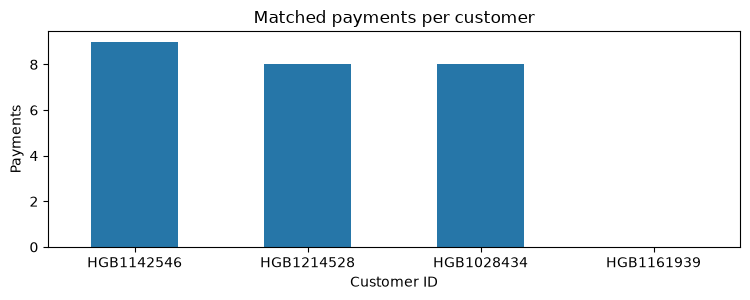

In [6]:
import matplotlib.pyplot as plt

counts = joined.set_index("customer_id")["transaction_count"]
ax = counts.plot.bar(figsize=(7.6, 3.1), color="#2676a8", rot=0)
ax.set(title="Matched payments per customer", xlabel="Customer ID", ylabel="Payments")
plt.tight_layout()
plt.show()

## 5 · Compare features with a random reference

**What we’re doing.** Compare the link between salary and the payment summaries with the link between salary and random numbers.

**Why we’re doing it.** Even random numbers can look related by chance. This gives us a rough comparison before deciding which clues to test more carefully.

**What to look for.** Even random data can give a non-zero score. The course lab uses mutual information, which can find some relationships missed by correlation.

In [7]:
salary_text = customers["monthly_salary_aed"].astype("string")
salary_text = salary_text.str.replace("AED", "", regex=False).str.replace(",", "", regex=False).str.strip()
customers["salary"] = pd.to_numeric(salary_text, errors="coerce")
checked = customers.join(features, on="customer_id")
labelled = checked[(checked["salary_transfer"] == 1) & (checked["salary"] > 0)]
labelled = labelled.dropna(subset=["spend_aed", "transaction_count"]).copy()
labelled["random_reference"] = np.random.default_rng(42).normal(size=len(labelled))
probes = ["spend_aed", "transaction_count", "random_reference"]
display(labelled[probes].corrwith(labelled["salary"]).round(3).rename("Correlation with salary"))

spend_aed            0.074
transaction_count    0.001
random_reference     0.002
Name: Correlation with salary, dtype: float64

## 6 · Check the final table

**What we’re doing.** Print the final columns and confirm each customer appears once.

**Why we’re doing it.** Another analyst needs to know what one row means, which days it covers and how we treated missing records.

**What to look for.** The customer ID is unique. Recency is in days, and spend covers only the supplied event slice.

In [8]:
delivery_columns = ["customer_id", "days_since_last_event", "transaction_count", "spend_aed", "has_activity"]
display(joined[delivery_columns].round(2))
print("One row per customer:", joined["customer_id"].is_unique)
print("Cutoff used:", cutoff.date())

,customer_id,days_since_last_event,transaction_count,spend_aed,has_activity
0,HGB1142546,2.0,9.0,6526.77,True
1,HGB1214528,2.0,8.0,10359.51,True
2,HGB1028434,3.0,8.0,6479.87,True
3,HGB1161939,NaN,0.0,0.00,False


One row per customer: True
Cutoff used: 2025-04-05


**Handoff.** The course lab saves a full feature table and a description of
its columns. This four-row example shows the table shape and its rules.
Use the supplied full-course checkpoints when running the original labs.

### Your turn

Choose one of the IDs in the first output. Find it in the final table and
explain why its transaction count can be larger than the number of rows
shown in the preview.